# Cells, molecules, and Hilbert space: one master equation
### cell physiology → quantum mechanics → quantum information → computer science

| field | object | equation | conserved |
|---|---|---|---|
| cell physiology | ion channel, closed ⇄ open | $\dot p = Q\,p$ (master equation) | $\sum_i p_i$ (L1 norm) |
| molecules / QM | excitation shared by two chromophores | $\dot\psi=-iH\psi$ (Schrödinger) | $\|\psi\|^2$ (L2 norm) |
| QIS | the same molecule in a warm cell | $\dot\rho=-i[H,\rho]-\gamma(\rho-\mathrm{diag}\,\rho)$ (Lindblad) | $\mathrm{Tr}\,\rho$ |
| CS | simulating any of these | $\exp$ of a matrix | memory $\sim 4^N$ |

The punchline is in §5. When the environment dephases the molecule strongly, the quantum
equation **becomes** the ion-channel equation, with a hopping rate
$k=2J^2\gamma/(\gamma^2+\Delta^2)$. Decoherence is the bridge from Hilbert space to the Markov
chains of physiology.

Energies are in cm⁻¹, as in spectroscopy, and times in femtoseconds. The parameters are
illustrative magnitudes, not fits to a real protein. Whether quantum coherence *matters* for
photosynthesis at body temperature is still debated in the research literature. This notebook
shows the mechanism; it doesn't settle that debate.

In [1]:
import numpy as np, matplotlib.pyplot as plt
import sympy as sp
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
from dgs import cell_hilbert_bridge as c
sp.init_printing()
print(f"k_B T at 310 K = {c.thermal_energy_cm():.1f} cm^-1   (compare with couplings J ~ 20-100 cm^-1)")
print(f"100 cm^-1 = {c.cm_to_rad_per_fs(100):.4f} rad/fs  ->  period {2*np.pi/c.cm_to_rad_per_fs(100):.0f} fs")

k_B T at 310 K = 215.5 cm^-1   (compare with couplings J ~ 20-100 cm^-1)
100 cm^-1 = 0.0188 rad/fs  ->  period 334 fs


## 1. Cell physiology: one ion channel is a random telegraph

A voltage-gated K⁺ channel is a protein that is either **closed** or **open**. It hops between
the two with rates $k_o$ (opening) and $k_c$ (closing), so each dwell time is exponential with
mean $1/k$. This is the Gillespie algorithm, the same one used for chemical kinetics. A
patch-clamp amplifier sees the result directly: a current that jumps between $0$ and
$i=\gamma_{\text{ch}}(V-E_K)$, where $E_K$ is the Nernst potential from
`dgs.membrane_biophysics`.

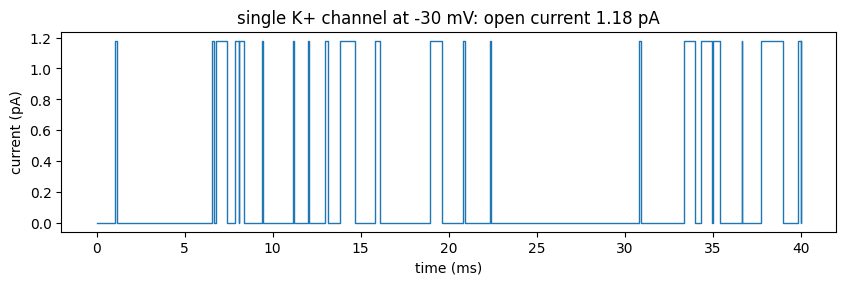

time-averaged p_open = 0.2488   theory k_o/(k_o+k_c) = 0.2500


In [2]:
ko, kc = 1.0, 3.0            # 1/ms
t, s = c.telegraph_trace(ko, kc, 40.0, rng=1)
i_open = c.single_channel_current_pA(-30)
fig, ax = plt.subplots(figsize=(10, 2.6))
ax.step(t, s * i_open, where="post", lw=1)
ax.set_xlabel("time (ms)"); ax.set_ylabel("current (pA)")
ax.set_title(f"single K+ channel at -30 mV: open current {i_open:.2f} pA")
plt.show()
T, S = c.telegraph_trace(ko, kc, 50000.0, rng=2)
print(f"time-averaged p_open = {c.time_average_open(T, S):.4f}   theory k_o/(k_o+k_c) = {c.stationary_open_probability(ko, kc):.4f}")

## 2. The master equation, solved by a matrix exponential

Average over many channels and the noise turns into a smooth ODE, $\dot p=Qp$, with solution
$p(t)=e^{Qt}p_0$. Every column of $Q$ sums to zero, which conserves total probability. The steady
state is the null vector of $Q$, solved here in SymPy:

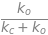

In [3]:
c.derive_master_stationary()

Q =
 [[-1.  3.]
 [ 1. -3.]] 
column sums: [0. 0.]  eigenvalues: [ 0. -4.]


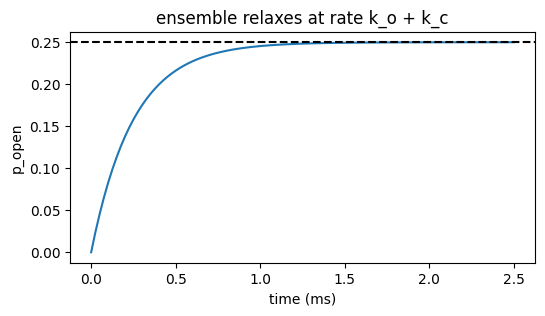

In [4]:
Q = c.channel_generator(ko, kc)
ts = np.linspace(0, 2.5, 200)
p = c.master_evolve(Q, [1, 0], ts)
print("Q =\n", Q, "\ncolumn sums:", Q.sum(axis=0), " eigenvalues:", np.linalg.eigvals(Q))
plt.figure(figsize=(6, 3)); plt.plot(ts, p[:, 1]); plt.axhline(c.stationary_open_probability(ko, kc), ls="--", c="k")
plt.xlabel("time (ms)"); plt.ylabel("p_open"); plt.title("ensemble relaxes at rate k_o + k_c"); plt.show()

The eigenvalues are $0$ (the steady state) and $-(k_o+k_c)$ (the relaxation rate). This is a
2-state version of a Hodgkin–Huxley gate: the HH variable $n$ obeys exactly
$\dot n=\alpha(1-n)-\beta n$.

## 3. Molecules in Hilbert space: the excitonic dimer

A photon absorbed by a light-harvesting complex creates an electronic **excitation** that can sit
on chromophore 1 or chromophore 2. Those two possibilities are basis vectors $|1\rangle,|2\rangle$
of a 2-dimensional Hilbert space, mathematically a qubit:

$$H=\begin{pmatrix}\Delta/2 & J\\ J & -\Delta/2\end{pmatrix},$$

where $\Delta$ is the energy gap between the two sites and $J$ is their dipole–dipole coupling.
Start on site 1 and SymPy diagonalizes $e^{-iHt}$ to give the **Rabi formula**:

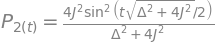

SymPy (exact P2) - (Rabi formula) = 0


In [5]:
P2, target, diff = c.derive_rabi()
display(sp.Eq(sp.Symbol("P_2(t)"), target)); print("SymPy (exact P2) - (Rabi formula) =", diff)

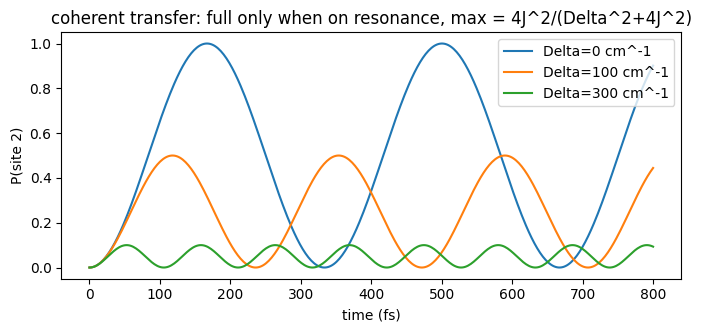

In [6]:
ts = np.linspace(0, 800, 400)
fig, ax = plt.subplots(figsize=(8, 3.2))
for d in (0, 100, 300):
    ax.plot(ts, c.rabi_population(ts, d, 50), label=f"Delta={d} cm^-1")
ax.set_xlabel("time (fs)"); ax.set_ylabel("P(site 2)"); ax.legend()
ax.set_title("coherent transfer: full only when on resonance, max = 4J^2/(Delta^2+4J^2)"); plt.show()

In the quantum case, probability doesn't flow one way and settle as in §2. It **oscillates**,
because amplitudes interfere. With detuning the transfer is never complete. That's a problem
for a molecule whose job is to deliver energy downhill.

## 4. QIS: the density matrix and dephasing

A cell is warm (k_BT ≈ 215 cm⁻¹ at 310 K, comparable to J) and full of fluctuating water and
protein. Those fluctuations jiggle the site energies, and so continually "ask" which site the
excitation is on. In the **density matrix** $\rho$, this shows up as decay of the off-diagonal
coherences $\rho_{12}$ at rate $\gamma$ (pure dephasing, a Lindblad term). Three QIS diagnostics:

* **purity** $\mathrm{Tr}\rho^2$: 1 for a pure state, ½ for maximally mixed;
* **von Neumann entropy** in bits;
* the **Bloch vector**, whose length is 1 for a pure state and 0 for maximally mixed.

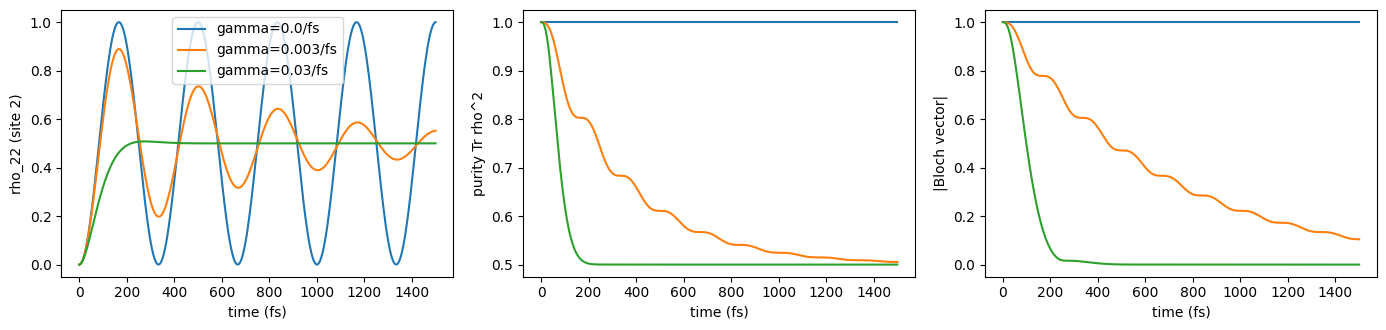

long time, gamma=0.2: rho =
 [[0.5+0.j 0. +0.j]
 [0. -0.j 0.5+0.j]] 
entropy = 1.0 bits


In [7]:
H = c.dimer_hamiltonian(0, 50)
rho0 = c.projector(c.site_ket(0))
ts = np.linspace(0, 1500, 300)
fig, axs = plt.subplots(1, 3, figsize=(14, 3.4))
for g in (0.0, 0.003, 0.03):
    R = c.evolve_density(H, rho0, ts, gamma=g)
    axs[0].plot(ts, R[:, 1, 1].real, label=f"gamma={g}/fs")
    axs[1].plot(ts, [c.purity(r) for r in R])
    axs[2].plot(ts, [np.linalg.norm(c.bloch_vector(r)) for r in R])
axs[0].set_ylabel("rho_22 (site 2)"); axs[1].set_ylabel("purity Tr rho^2"); axs[2].set_ylabel("|Bloch vector|")
for a in axs: a.set_xlabel("time (fs)")
axs[0].legend(); plt.tight_layout(); plt.show()
r_end = c.evolve_density(H, rho0, [10000.0], gamma=0.2)[0]
print("long time, gamma=0.2: rho =\n", np.round(r_end, 4), "\nentropy =", round(c.von_neumann_entropy_bits(r_end), 4), "bits")

## 5. The bridge: strong dephasing turns quantum into classical

Let the coherence $\rho_{12}$ relax fast (it follows the populations adiabatically). Set
$\dot\rho_{12}=0$, solve for $\rho_{12}$, and substitute into $\dot\rho_{11}$. SymPy does the
algebra:

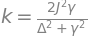

In [8]:
k_sym = c.derive_incoherent_rate()
display(sp.Eq(sp.Symbol("k"), k_sym))

So $\dot\rho_{11}=k(\rho_{22}-\rho_{11})$. That is **exactly** the ion-channel master
equation of §2, with $k_o=k_c=k$. The two rates are equal because pure dephasing acts like an
infinite-temperature bath; a real bath adds detailed balance, $k_{\downarrow}/k_{\uparrow}=e^{\Delta/k_BT}$.
The check below runs the full quantum Lindblad equation against the *same function* used for
the ion channel:

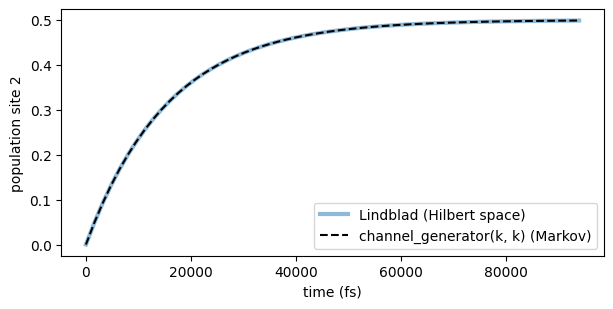

k = 3.193e-05 /fs   max |difference| = 1.29e-05


In [9]:
d, J, g = 150.0, 30.0, 2.0
k = c.incoherent_rate(d, J, g)
ts = np.linspace(0, 3 / k, 60)
quantum = c.evolve_density(c.dimer_hamiltonian(d, J), rho0, ts, gamma=g)[:, 1, 1].real
classical = c.master_evolve(c.channel_generator(k, k), [1, 0], ts)[:, 1]
plt.figure(figsize=(7, 3.2))
plt.plot(ts, quantum, lw=3, alpha=.5, label="Lindblad (Hilbert space)")
plt.plot(ts, classical, "k--", label="channel_generator(k, k) (Markov)")
plt.xlabel("time (fs)"); plt.ylabel("population site 2"); plt.legend(); plt.show()
print(f"k = {k:.3e} /fs   max |difference| = {np.max(np.abs(quantum - classical)):.2e}")

## 6. Noise that helps: dephasing-assisted transport

Add a **sink** on site 2 (the reaction center, trapping time 1 ps) and a slow **loss** from every
site (recombination, 20 ps). The yield is $\eta=\kappa\int_0^\infty\rho_{22}\,dt$, computed
exactly as $-\mathcal L^{-1}$ instead of by time-stepping.

* $\gamma\to0$: the detuned dimer oscillates and never fully delivers (§3).
* $\gamma\to\infty$: $k\approx2J^2/\gamma\to0$, a **quantum Zeno** freeze. Watching too often stops the transfer.
* In between there is an optimum, near $\gamma\approx\Delta$, where $k$ is largest.

In the research literature this effect is called environment-assisted quantum transport.

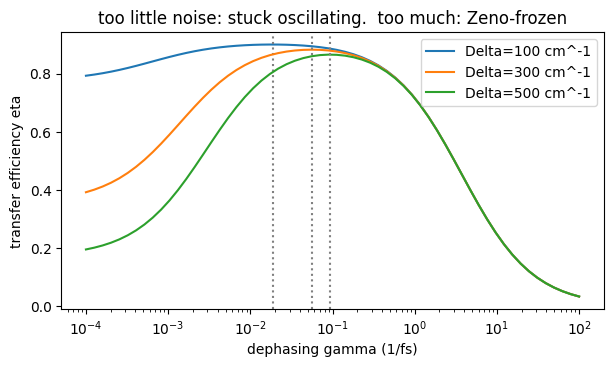

In [10]:
gs = np.logspace(-4, 2, 60)
fig, ax = plt.subplots(figsize=(7, 3.6))
for d in (100, 300, 500):
    ax.semilogx(gs, [c.transfer_efficiency(d, 50, g) for g in gs], label=f"Delta={d} cm^-1")
    ax.axvline(c.cm_to_rad_per_fs(d), ls=":", c="gray")
ax.set_xlabel("dephasing gamma (1/fs)"); ax.set_ylabel("transfer efficiency eta"); ax.legend()
ax.set_title("too little noise: stuck oscillating.  too much: Zeno-frozen"); plt.show()

## 7. Computer science: what Hilbert space costs

A dimer is cheap. A full description of $N$ two-level molecules (or $N$ qubits) takes
$2^N$ amplitudes, and its density matrix $4^N$. Photosynthesis is lucky: one photon makes one
excitation, so it lives in the **single-excitation manifold** of dimension $N$. The FMO complex
(7–8 chromophores) is a 7×7 problem, not a $2^7$ one.

In [11]:
for n in (2, 7, 10, 20, 30):
    full = c.hilbert_memory_bytes(n, "density")
    single = c.hilbert_memory_bytes(n, "density", "single")
    print(f"N={n:2d}  full rho: {full:12.3e} B   single-excitation rho: {single:6d} B")

N= 2  full rho:    2.560e+02 B   single-excitation rho:     64 B
N= 7  full rho:    2.621e+05 B   single-excitation rho:    784 B
N=10  full rho:    1.678e+07 B   single-excitation rho:   1600 B
N=20  full rho:    1.759e+13 B   single-excitation rho:   6400 B
N=30  full rho:    1.845e+19 B   single-excitation rho:  14400 B


Above about 15 coupled sites, the full density matrix no longer fits in RAM. That
exponential wall is why quantum chemistry needs clever approximations, and why simulating
molecules is the flagship application proposed for quantum computers.

## 8. The ladder in one picture

* **Physiology:** stochastic gating, $\dot p=Qp$, L1-conserving.
* **QM:** unitary $e^{-iHt}$, L2-conserving, interference.
* **QIS:** $\rho$, purity, entropy, and the Lindblad equation that interpolates between the two.
* **CS:** every one of them is `expm(matrix * t) @ vector`. The cost is set by the dimension:
  $n$ classically, $2^N$ (state vector) or $4^N$ (density matrix) quantum mechanically.

*All data are synthetic; parameters are illustrative, not fits to a real channel or protein.*